<a href="https://colab.research.google.com/github/davalagishiva-code/AIML/blob/main/outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [61]:
df=pd.read_csv("https://aicsvv.netlify.app/marks.csv")
df

,Reg_no,OSA,CN
0,393CS22706,44.0,45.0
1,393CS22707,97.0,47.0
2,393CS22704,97.0,-36.0
3,393CS22705,NaN,52.0
4,393CS22701,75.0,21.0
5,393CS21039,11.0,NaN
6,393CS21013,87.0,92.0
7,393CS21017,45.0,78.0
8,393CS21024,NaN,17.0
9,393CS21006,97.0,47.0


In [62]:
df.isnull().sum()

,0
Reg_no,0
OSA,4
CN,2


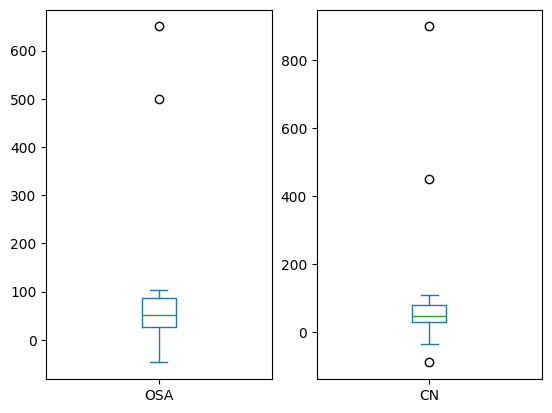

In [63]:
df.plot(kind='box',subplots=True)
plt.show()

In [64]:
q1=df['CN'].quantile(0.25)
q3=df['CN'].quantile(0.75)
iqr=q3-q1
low_limit=q1-1.5*iqr
high_limit=q3+1.5*iqr
outliers=df[(df['CN']<low_limit) | (df['CN']>high_limit)]
outliers

,Reg_no,OSA,CN
10,393CS21041,23.0,450.0
16,393CS21022,22.0,-89.0
25,393CS21010,76.0,900.0


In [65]:
df.drop(outliers.index,inplace=True)
df

,Reg_no,OSA,CN
0,393CS22706,44.0,45.0
1,393CS22707,97.0,47.0
2,393CS22704,97.0,-36.0
3,393CS22705,NaN,52.0
4,393CS22701,75.0,21.0
5,393CS21039,11.0,NaN
6,393CS21013,87.0,92.0
7,393CS21017,45.0,78.0
8,393CS21024,NaN,17.0
9,393CS21006,97.0,47.0


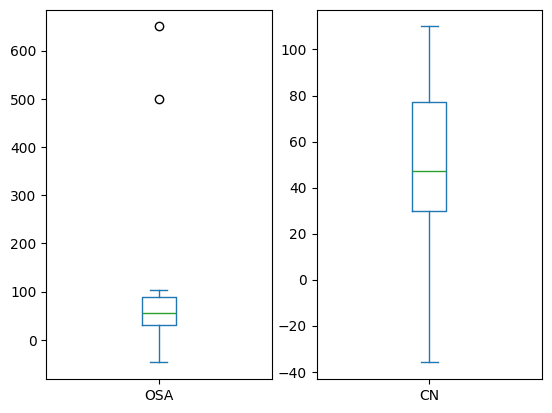

In [66]:
df.plot(kind='box',subplots=True)
plt.show()

In [67]:
df.shape

(39, 3)

In [68]:
high_limit=df['OSA'].quantile(0.9)
high_limit
low_limit=df['OSA'].quantile(0.1)
low_limit
df['OSA']=np.where(df['OSA']>high_limit,high_limit,
np.where(df['OSA']<=low_limit,low_limit,df['OSA']))

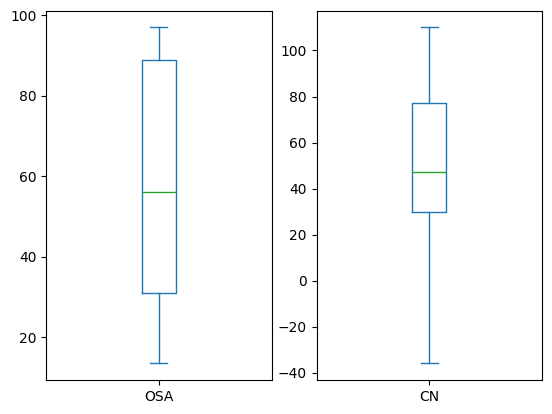

In [69]:
df.plot(kind='box',subplots=True)
plt.show()

In [71]:
df['CN1']=df['CN'].map(lambda i:np.log(i) if i>0 else 0)
display(df['CN'].skew())
display(df['CN1'].skew())

np.float64(-0.29802112453924984)

np.float64(-1.8488323490058103)